# A2 - Solver plots and accuracy checks

This notebook demonstrates the atmospheric-entry solver, the energy-deposition calculation, and outcome classification. It measures accuracy in two cases: an intact body compared with the analytical solution, and a fragmenting body compared with a finer-step numerical reference.

The intact-body comparison uses an exponential atmosphere, no gravity, no lift, no ablation, no fragmentation, and a flat planet. Those assumptions match the analytical model. The fragmentation convergence comparison uses the smallest tested time step as a numerical reference; it is an estimate of convergence, not an exact solution.

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from deepimpact.solver import Planet

plt.style.use("seaborn-v0_8-whitegrid")
%matplotlib inline

## 1. Intact body: numerical solution versus analytical solution

The solver is run with several output time steps. The left plot compares numerical speed with the analytical speed at the same altitudes. The middle plot shows the relative error along the descent at regular output samples. The right plot summarizes the maximum relative error at those samples, excluding the initial condition and the linearly interpolated ground-crossing point. The x-axis is output dt; for these runs the internal RK4 step is h=dt/2, so the expected fourth-order slope is unchanged. The dashed fourth-order guide is anchored at the coarsest measured error and is not a fit.


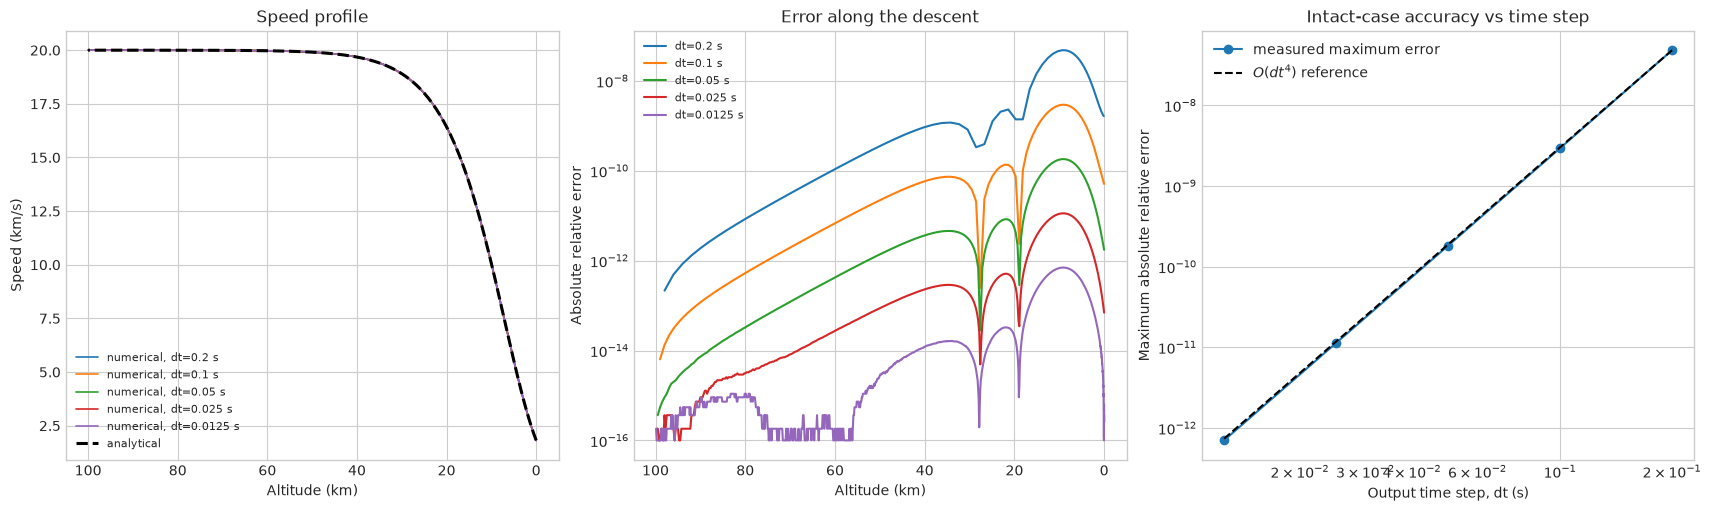

,dt (s),max relative speed error,final numerical speed (m/s),final altitude (m)
0,0.2000,4.817390e-08,1814.433326,0.0
1,0.1000,2.937884e-09,1814.397970,0.0
2,0.0500,1.816802e-10,1814.380127,0.0
3,0.0250,1.128788e-11,1814.376815,0.0
4,0.0125,7.010826e-13,1814.375405,0.0


In [18]:
# Scenario and model assumptions (SI units unless stated otherwise)
radius = 1.0                  # m
body_density = 3000.0         # kg/m^3
initial_speed = 20_000.0      # m/s
entry_angle = 30.0            # degrees from horizontal
initial_altitude = 100_000.0  # m
sea_level_density = 1.2       # kg/m^3
scale_height = 8_000.0        # m
initial_mass = (4.0 / 3.0) * np.pi * radius**3 * body_density
intact_time_steps = [0.2, 0.1, 0.05, 0.025, 0.0125]

# Match the analytical model assumptions: g=0, no lift/ablation,
# exponential atmosphere, flat planet, and no breakup (strength=infinity).
intact_planet = Planet(
    atmos_func="exponential", Cd=1.0, Ch=0.0, Cl=0.0, g=0.0,
    H=scale_height, rho0=sea_level_density, Rp=np.inf
)

intact_runs = {}
intact_errors = {}
for dt in intact_time_steps:
    result = intact_planet.solve_atmospheric_entry(
        radius=radius,
        velocity=initial_speed,
        density=body_density,
        strength=np.inf,
        angle=entry_angle,
        init_altitude=initial_altitude,
        dt=dt,
    )
    z = result["altitude"].to_numpy()
    numerical_speed = result["velocity"].to_numpy()
    analytical_speed = intact_planet.analytical_solution(
        z,
        v0=initial_speed,
        C_D=intact_planet.Cd,
        R=radius,
        m0=initial_mass,
        theta=entry_angle,
        rho_0=sea_level_density,
        H=scale_height,
        z0=initial_altitude,
    )
    relative_error = np.abs(numerical_speed - analytical_speed) / np.maximum(
        np.abs(analytical_speed), 1.0
    )
    intact_runs[dt] = result
    intact_errors[dt] = relative_error

# A smooth analytical curve provides context for the sampled solver curves.
altitude_grid = np.linspace(0.0, initial_altitude, 600)
analytical_curve = intact_planet.analytical_solution(
    altitude_grid,
    v0=initial_speed,
    C_D=intact_planet.Cd,
    R=radius,
    m0=initial_mass,
    theta=entry_angle,
    rho_0=sea_level_density,
    H=scale_height,
    z0=initial_altitude,
)

fig, axes = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)
for dt, result in intact_runs.items():
    axes[0].plot(
        result["altitude"] / 1000,
        result["velocity"] / 1000,
        linewidth=1.2,
        label=f"numerical, dt={dt:g} s",
    )
    axes[1].semilogy(
        result["altitude"].to_numpy()[1:-1] / 1000,
        np.maximum(intact_errors[dt][1:-1], 1e-16),
        label=f"dt={dt:g} s",
    )
axes[0].plot(
    altitude_grid / 1000,
    analytical_curve / 1000,
    "k--",
    linewidth=2.2,
    label="analytical",
)
axes[0].set(xlabel="Altitude (km)", ylabel="Speed (km/s)", title="Speed profile")
axes[1].set(
    xlabel="Altitude (km)",
    ylabel="Absolute relative error",
    title="Error along the descent",
)

max_relative_errors = [
    np.max(intact_errors[dt][1:-1]) for dt in intact_time_steps
]
reference_order = 4
reference_errors = max_relative_errors[0] * (
    np.asarray(intact_time_steps) / intact_time_steps[0]
) ** reference_order
axes[2].loglog(
    intact_time_steps,
    max_relative_errors,
    "o-",
    label="measured maximum error",
)
axes[2].loglog(
    intact_time_steps,
    reference_errors,
    "k--",
    label=r"$O(dt^4)$ reference",
)
axes[2].set(
    xlabel="Output time step, dt (s)",
    ylabel="Maximum absolute relative error",
    title="Intact-case accuracy vs time step",
)
axes[2].legend()
for ax in axes[:2]:
    ax.invert_xaxis()
    ax.legend(fontsize=8)
plt.show()

intact_accuracy = pd.DataFrame(
    {
        "dt (s)": intact_time_steps,
        "max relative speed error": max_relative_errors,
        "final numerical speed (m/s)": [
            intact_runs[dt]["velocity"].iloc[-1] for dt in intact_time_steps
        ],
        "final altitude (m)": [
            intact_runs[dt]["altitude"].iloc[-1] for dt in intact_time_steps
        ],
    }
)
intact_accuracy


## 2. Fragmentation case: trajectory, energy deposition, and outcome

This is a Chelyabinsk-like entry scenario. `calculate_energy` adds `dedz` to the solver result, and `analyse_outcome` uses that result to report the event classification and burst properties. The dashed horizontal line marks the first sampled altitude where the radius has grown, as an approximate visual indicator of breakup onset; the peak-deposition marker is the row used to report the burst altitude.


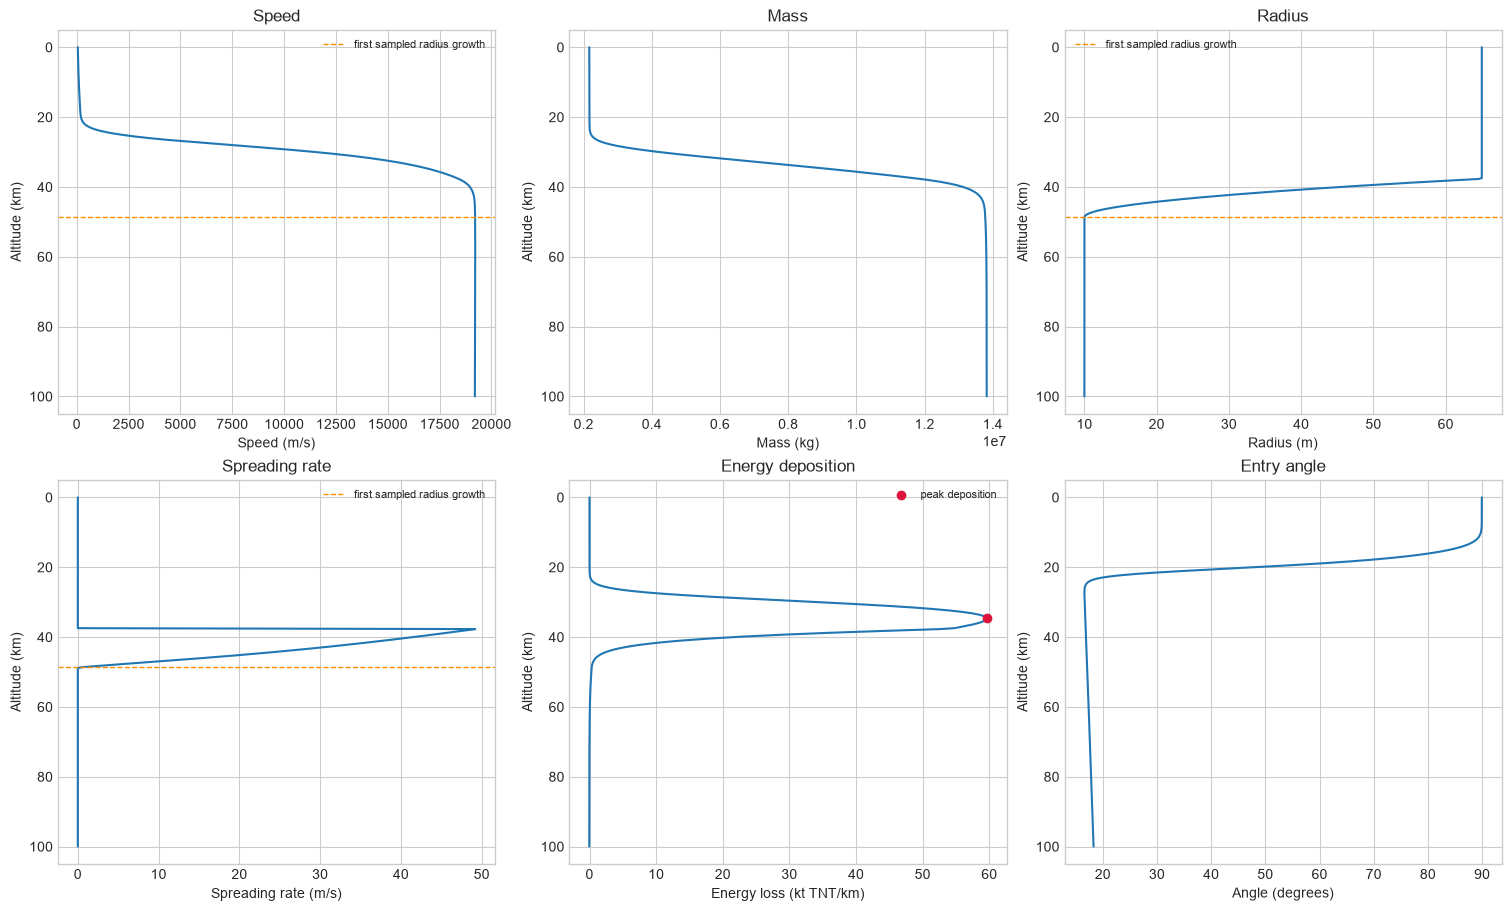

Outcome summary:
outcome: Airburst
burst_peak_dedz: 59.61198869115032
burst_altitude: 34647.52306239146
burst_distance: 204626.5102676428
burst_energy: 303.59725752628106
burst_angle: 16.770674358320683
First sampled radius-growth altitude: 48579.1 m


In [3]:
fragment_planet = Planet()
fragment_parameters = {
    "radius": 10.0,             # m
    "velocity": 19_200.0,       # m/s
    "density": 3300.0,          # kg/m^3
    "strength": 1.0e6,          # Pa
    "angle": 18.3,              # degrees from horizontal
    "init_altitude": 100_000.0, # m
    "dt": 0.05,                 # s
}
fragment_trajectory = fragment_planet.solve_atmospheric_entry(
    **fragment_parameters
)
fragment_energy = fragment_planet.calculate_energy(fragment_trajectory)
fragment_outcome = fragment_planet.analyse_outcome(fragment_energy)

initial_radius = fragment_parameters["radius"]
grown_rows = np.flatnonzero(
    fragment_trajectory["radius"].to_numpy() > initial_radius * (1 + 1e-8)
)
breakup_altitude = (
    fragment_trajectory["altitude"].iloc[grown_rows[0]]
    if len(grown_rows)
    else None
)
peak_position = int(np.nanargmax(fragment_energy["dedz"].to_numpy()))
peak_row = fragment_energy.iloc[peak_position]

fig, axes = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
plot_specs = [
    ("velocity", "Speed (m/s)", "Speed"),
    ("mass", "Mass (kg)", "Mass"),
    ("radius", "Radius (m)", "Radius"),
    ("spreading_rate", "Spreading rate (m/s)", "Spreading rate"),
    ("dedz", "Energy loss (kt TNT/km)", "Energy deposition"),
    ("angle", "Angle (degrees)", "Entry angle"),
]
for ax, (column, xlabel, title) in zip(axes.flat, plot_specs):
    source = fragment_energy if column == "dedz" else fragment_trajectory
    ax.plot(source[column], source["altitude"] / 1000, linewidth=1.5)
    ax.set(xlabel=xlabel, ylabel="Altitude (km)", title=title)
    ax.invert_yaxis()

if breakup_altitude is not None:
    for ax in [axes[0, 0], axes[0, 2], axes[1, 0]]:
        ax.axhline(
            breakup_altitude / 1000,
            color="darkorange",
            linestyle="--",
            linewidth=1,
            label="first sampled radius growth",
        )
        ax.legend(fontsize=8)
axes[1, 1].scatter(
    [peak_row["dedz"]],
    [peak_row["altitude"] / 1000],
    color="crimson",
    zorder=3,
    label="peak deposition",
)
axes[1, 1].legend(fontsize=8)
plt.show()

print("Outcome summary:")
for key, value in fragment_outcome.items():
    print(f"{key}: {value}")
print(f"First sampled radius-growth altitude: {breakup_altitude:.1f} m" if breakup_altitude is not None else "No radius growth sampled")


## 3. Fragmentation case: timestep convergence

The solver is run with the same entry parameters at several time steps. Each output trajectory is interpolated onto a shared altitude grid restricted to the altitude range common to every run. The finest tested time step is the reference. The plotted errors are the maximum absolute differences in speed, mass, and radius, scaled by the maximum absolute reference value of each variable and expressed as percentages.

The breakup condition is a threshold event, so coarse-step errors need not decrease perfectly at every halving: a step can cross the breakup threshold at a slightly different point. The finer-step trend is the more useful indication of convergence.

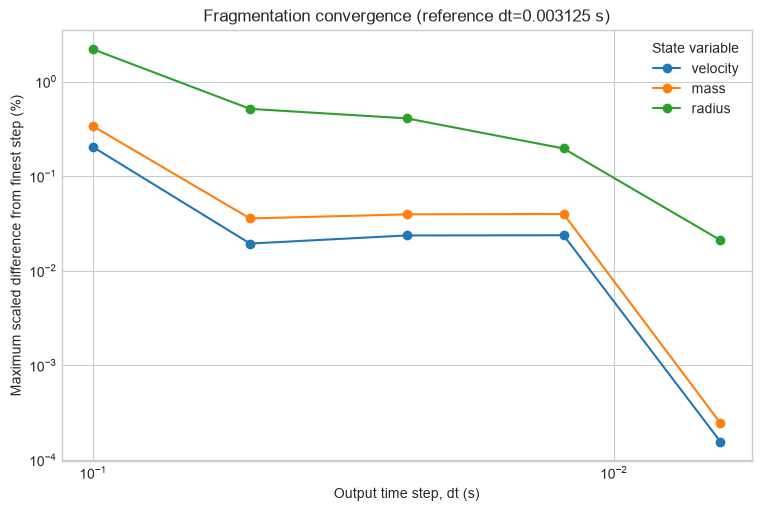

,dt (s),velocity difference (%),mass difference (%),radius difference (%),final altitude (m)
0,0.100000,0.202135,0.335970,2.184489,0.0
1,0.050000,0.019376,0.035699,0.513973,0.0
2,0.025000,0.023605,0.039430,0.407983,0.0
3,0.012500,0.023717,0.039802,0.195996,0.0
4,0.006250,0.000157,0.000246,0.021070,0.0
5,0.003125,0.000000,0.000000,0.000000,0.0


In [4]:
fragment_time_steps = [0.1, 0.05, 0.025, 0.0125, 0.00625, 0.003125]
fragment_runs = {
    dt: fragment_planet.solve_atmospheric_entry(
        **{**fragment_parameters, "dt": dt}
    )
    for dt in fragment_time_steps
}
reference_dt = min(fragment_time_steps)
reference_run = fragment_runs[reference_dt]

# Use only altitudes covered by every run, avoiding endpoint extrapolation.
common_low_altitude = max(run["altitude"].min() for run in fragment_runs.values())
common_high_altitude = min(run["altitude"].max() for run in fragment_runs.values())
common_altitudes = np.linspace(common_low_altitude, common_high_altitude, 500)
variables = ["velocity", "mass", "radius"]
scaled_differences = {name: [] for name in variables}

for dt in fragment_time_steps:
    run = fragment_runs[dt]
    run_altitude = run["altitude"].to_numpy()[::-1]
    ref_altitude = reference_run["altitude"].to_numpy()[::-1]
    for name in variables:
        run_values = run[name].to_numpy()[::-1]
        ref_values = reference_run[name].to_numpy()[::-1]
        values_on_grid = np.interp(common_altitudes, run_altitude, run_values)
        reference_on_grid = np.interp(common_altitudes, ref_altitude, ref_values)
        scale = max(np.max(np.abs(reference_on_grid)), 1.0)
        max_scaled_difference = np.max(
            np.abs(values_on_grid - reference_on_grid)
        ) / scale
        scaled_differences[name].append(max_scaled_difference)

fig, ax = plt.subplots(figsize=(7.5, 5), constrained_layout=True)
for name in variables:
    # The finest run is the reference and therefore has zero self-difference.
    ax.loglog(
        fragment_time_steps[:-1],
        np.asarray(scaled_differences[name][:-1]) * 100,
        "o-",
        label=name,
    )
ax.set(
    xlabel="Output time step, dt (s)",
    ylabel="Maximum scaled difference from finest step (%)",
    title=f"Fragmentation convergence (reference dt={reference_dt:g} s)",
)
ax.invert_xaxis()
ax.legend(title="State variable")
plt.show()

fragment_convergence = pd.DataFrame(
    {
        "dt (s)": fragment_time_steps,
        **{
            f"{name} difference (%)": np.asarray(values) * 100
            for name, values in scaled_differences.items()
        },
        "final altitude (m)": [
            fragment_runs[dt]["altitude"].iloc[-1] for dt in fragment_time_steps
        ],
    }
)
fragment_convergence
